# 2026 지옥캠프: 6공학관 vs IT관 분류 — 베이스라인 (사전학습 모델 4종 비교)

EfficientNet-B0, ResNet18 Places365, ResNet18, MobileNetV3 Large를 같은 데이터 분할과 학습 설정에서 각각 3회 비교합니다. 실행별 그래프와 전체 통계를 저장하고, 선택한 모델로 제출 CSV와 모델 패키지를 생성합니다.

- 작성 환경: Google Colab (CPU만으로도 동작) / 로컬 Python 3.10+, PyTorch 2.x
- GPU가 있으면 자동으로 사용하지만 **필수는 아닙니다**

## 대회 규칙 요약 (필독)

| 항목 | 내용 |
|---|---|
| 과제 | 사진 → **6공학관(0) / IT관(1)** 이진 분류 |
| 참가 | 개인전 |
| 기간 | 2026-11-07(토) ~ 11-08(일) |
| 지표 | **Log Loss** (낮을수록 우수, 확률을 제출해야 함) |
| 모델 제약 | **총 파라미터 20M 이하** (앙상블·사전학습 백본 합산) |
| 런타임 | **Colab CPU 기준** 테스트 500장 10분 이내 · 실행 중 다운로드 금지 (사전학습 가중치는 최종 파일에 포함) |
| 금지 | 외부 이미지 사용, 테스트 이미지를 학습에 사용(pseudo-labeling 포함) |
| 제출 | 예측 CSV **10분에 1회 · 하루 최대 50회** (공개 리더보드) + 마감 시 최종 파일 1개 (형식 자유) |
| 순위 | 테스트 500장 중 Public 250장 = 공개 리더보드, **Private 250장 = 최종 순위** (어느 장이 Private 인지는 비공개) |


## 실행 전 사전 준비

### 모듈
Colab은 필요한 모듈이 모두 설치되어 있습니다. 로컬이라면:
```shell
# 본인 환경(CPU/CUDA)에 맞는 PyTorch 설치: https://pytorch.org/get-started/locally/
pip3 install torch torchvision
pip3 install -U scikit-learn matplotlib
```

### 데이터 파일
운영진이 배포한 데이터를 노트북과 같은 폴더에 압축해제해 주세요 (Colab 은 `/content`).
```
📁root
 ├─📁train
 │  ├─📁6e      ← 6공학관 (label 0)
 │  └─📁it      ← IT관   (label 1)
 ├─📁test       ← 테스트 500장 (Public 250 + Private 250)
 └─📜baseline.ipynb
```


## 모듈 불러오기 & 시드 고정

재현성을 위해 모든 난수 시드를 고정합니다. 시드가 고정되어 있어야 "내가 바꾼 것 때문에 점수가 오른 것인지, 운이 좋았던 것인지"를 구분할 수 있습니다.

In [1]:
import csv
import os
import random
import shutil
import subprocess
import time

import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Dataset, Subset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from PIL import Image


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)


SEED = 42
seed_everything(SEED)

In [3]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('사용 장치:', device)
if torch.cuda.is_available():
    print(torch.cuda.get_device_name())

사용 장치: cuda:0
NVIDIA GeForce RTX 3080


## 하이퍼 파라미터

In [4]:
params = {
    'epoch': 12,
    'batch_size': 32,
    'learning_rate': 1e-3,
    'valid_ratio': 0.15,   # 학습 2,906장 중 검증으로 떼어둘 비율
    'workers': 0,          # Windows 노트북의 워커 프로세스 멈춤 방지; 모든 실험에 공통 적용
    'num_show_img': 5,     # 데이터 확인용 표시 개수 (학습과 무관)
}

In [5]:
# label 0 = 6공학관(6e), label 1 = IT관(it)
class_names = {0: '6e', 1: 'it'}

MODEL_NAMES = (
	"efficientnet_b0",
	"resnet18_places365",
	"resnet18",
	"mobilenet_v3_large",
)
RUN_SEEDS = (42, 43, 44)


## 결과 폴더와 가중치 경로

현재 작업 폴더는 `train`, `test`, `baseline.ipynb`가 있는 `participant_materials`여야 합니다.
실행별 PNG 12개와 전체 비교 PNG는 `model_comparison/graphs`, 학습 가중치는 `model_comparison/checkpoints`, 통계 CSV는 `model_comparison`에 저장합니다.
각 epoch의 학습·검증 Log Loss와 정확도는 `model_comparison/epochs/{모델명}_seed{시드}.csv`에 한 행씩 저장합니다.
같은 시드로 다시 실행하면 기존 결과 파일을 덮어씁니다.


In [6]:
from pathlib import Path

BASE_DIR = Path.cwd().resolve()
assert (BASE_DIR / "train").is_dir(), f"작업 폴더에 train이 없습니다: {BASE_DIR}"

RESULT_DIR = BASE_DIR / "model_comparison"
GRAPH_DIR = RESULT_DIR / "graphs"
CHECKPOINT_DIR = RESULT_DIR / "checkpoints"
EPOCH_DIR = RESULT_DIR / "epochs"

GRAPH_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
EPOCH_DIR.mkdir(parents=True, exist_ok=True)

weight_path = BASE_DIR / "resnet18_places365.pth.tar"

print("그래프 저장 폴더:", GRAPH_DIR)
print("학습 가중치 저장 폴더:", CHECKPOINT_DIR)
print("Places365 가중치:", weight_path)


그래프 저장 폴더: \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\graphs
학습 가중치 저장 폴더: \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints
Places365 가중치: \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\resnet18_places365.pth.tar


### Places365 사전학습 가중치 — 최초 1회 다운로드

같은 경로에 파일이 있으면 재사용합니다. 다운로드가 끝난 뒤에만 `.part`를 최종 파일명으로 변경합니다.
나머지 세 모델의 ImageNet 가중치는 Torchvision이 처음 사용할 때 다운로드하고 이후 캐시를 재사용합니다.
Colab 런타임을 삭제하면 로컬 가중치와 캐시도 없어집니다. 제출 패키지의 추론 과정에서는 다운로드하지 않습니다.


In [7]:
import urllib.request

url = "http://places2.csail.mit.edu/models_places365/resnet18_places365.pth.tar"

if weight_path.is_file():
	print("기존 가중치 재사용:", weight_path)
else:
	temp_path = weight_path.with_name(weight_path.name + ".part")
	print("Places365 가중치 다운로드 시작", flush=True)
	urllib.request.urlretrieve(url, temp_path)
	temp_path.replace(weight_path)
	print("다운로드 완료:", weight_path)

print(f"파일 크기: {weight_path.stat().st_size / (1024 ** 2):.2f} MB")


Places365 가중치 다운로드 시작
다운로드 완료: \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\resnet18_places365.pth.tar
파일 크기: 43.40 MB


## 모델 정의 (`model.py` 생성)

아래 셀은 네 모델을 생성하는 `model.py`를 작성합니다. 모두 이진 분류용 logit 1개를 출력합니다.
학습 시 `pretrained=True`로 사전학습 가중치를 불러오며, 전체 파라미터를 학습합니다.
`pretrained=False`는 구조만 생성하므로 제출 패키지에서 다운로드 없이 저장된 학습 가중치를 불러올 수 있습니다.


In [8]:
%%writefile model.py
import torch
import torch.nn as nn
from torchvision import models

MODEL_NAME = "efficientnet_b0"

IMG_SIZE = 224
NORM_MEAN = (0.485, 0.456, 0.406)
NORM_STD = (0.229, 0.224, 0.225)


def build_model(model_name=MODEL_NAME, pretrained=False, places_weight_path=None):
	if model_name == "resnet18_places365":
		net = models.resnet18(weights=None, num_classes=365)
		if pretrained:
			if places_weight_path is None:
				raise ValueError("Places365 가중치 경로가 필요합니다.")
			checkpoint = torch.load(places_weight_path, map_location="cpu", weights_only=True)
			state_dict = {key.removeprefix("module."): value for key, value in checkpoint["state_dict"].items()}
			net.load_state_dict(state_dict)
		net.fc = nn.Linear(net.fc.in_features, 1)
	elif model_name == "resnet18":
		weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
		net = models.resnet18(weights=weights)
		net.fc = nn.Linear(net.fc.in_features, 1)
	elif model_name == "efficientnet_b0":
		weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
		net = models.efficientnet_b0(weights=weights)
		net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, 1)
	elif model_name == "mobilenet_v3_large":
		weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V2 if pretrained else None
		net = models.mobilenet_v3_large(weights=weights)
		net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, 1)
	else:
		raise ValueError(f"지원하지 않는 모델: {model_name}")
	return net


Overwriting model.py


In [9]:
import importlib
import model as model_module

importlib.reload(model_module)


<module 'model' from 'l:\\Workspaces\\Codex\\AID Study\\aid mini challenge\\participant_materials\\model.py'>

### 파라미터 제한

각 실행에서 모델을 새로 만들고 총 파라미터 수가 20,000,000 이하인지 확인합니다.
네 모델은 각각 비교하며 앙상블하지 않습니다.


In [10]:
PARAM_LIMIT = 20_000_000
print(f"비교 모델 {len(MODEL_NAMES)}개 × 시드 {len(RUN_SEEDS)}개 = 총 {len(MODEL_NAMES) * len(RUN_SEEDS)}회")


비교 모델 4개 × 시드 3개 = 총 12회


## 데이터 불러오기 & 증강

- 학습(train) 데이터에만 증강을 적용하고, 검증(valid) 데이터는 증강 없이 평가합니다.
- 두 transform 모두 마지막에 채널별 **정규화(Normalize)** 를 적용합니다. 픽셀 분포를 평균 0 근처로 맞추면 학습이 안정됩니다.
- 증강은 자유입니다 (flip·crop·color·noise·mixup 등). 다양하게 실험해 보세요.
- **주의**: 최종 순위는 공개 리더보드에 보이지 않는 Private 250장으로 정합니다. 공개 점수에 맞춰 튜닝하기보다 밝기·색감·화각 변화에 강한 모델을 만드는 것이 최종 점수에 유리합니다.


In [11]:
data_path = './train'

# 이미지 크기·정규화 상수는 model.py에 정의되어 있습니다 (predict.py와 공유).
IMG_SIZE = model_module.IMG_SIZE
NORM_MEAN = model_module.NORM_MEAN
NORM_STD = model_module.NORM_STD

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),  # 채널별 정규화
])

# 검증·추론용 전처리 — predict.py의 transform과 반드시 동일해야 합니다
valid_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])

# 같은 폴더를 transform만 다르게 두 번 로드한 뒤, 인덱스로 나눠 씁니다
full_train = datasets.ImageFolder(data_path, train_transform)
full_valid = datasets.ImageFolder(data_path, valid_transform)

print('클래스 → 라벨 매핑:', full_train.class_to_idx)
print('전체 이미지 수:', len(full_train))

클래스 → 라벨 매핑: {'6e': 0, 'it': 1}
전체 이미지 수: 2906


### Train / Valid 분할

클래스 비율이 유지되도록 층화(stratified) 분할합니다. 검증 점수(log loss)가 리더보드 점수의 예측치 역할을 하므로, **검증 데이터를 학습에 섞지 않도록** 주의하세요.

In [12]:
labels = [y for _, y in full_train.samples]
train_idx, valid_idx = train_test_split(
    list(range(len(full_train))),
    test_size=params['valid_ratio'],
    stratify=labels,
    random_state=SEED,
)

data_sets = {
    'train': Subset(full_train, train_idx),
    'valid': Subset(full_valid, valid_idx),
}
print(f"train: {len(data_sets['train'])}장 / valid: {len(data_sets['valid'])}장")

train: 2470장 / valid: 436장


In [13]:
g = torch.Generator()
g.manual_seed(SEED)

dataloaders = {
    'train': DataLoader(data_sets['train'], batch_size=params['batch_size'],
                        shuffle=True, num_workers=params['workers'], generator=g),
    'valid': DataLoader(data_sets['valid'], batch_size=params['batch_size'],
                        shuffle=False, num_workers=params['workers']),
}
print('배치 수 — train: %d / valid: %d' % (len(dataloaders['train']), len(dataloaders['valid'])))

배치 수 — train: 78 / valid: 14


### 데이터 확인

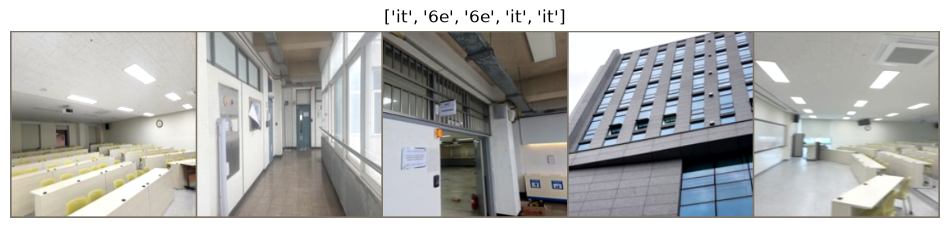

In [14]:
def img_show(tensor, title=None):
    arr = tensor.numpy().transpose((1, 2, 0))
    arr = arr * np.array(NORM_STD) + np.array(NORM_MEAN)  # 정규화 되돌리기 (표시용)
    arr = np.clip(arr, 0, 1)
    plt.figure(figsize=(12, 4))
    plt.imshow(arr)
    plt.axis('off')
    if title is not None:
        plt.title(title)
    plt.show()


inputs, classes = next(iter(dataloaders['train']))
out = torchvision.utils.make_grid(inputs[:params['num_show_img']])
img_show(out, title=[class_names[int(c)] for c in classes[:params['num_show_img']]])

## 학습 — 4개 모델 × 3회

기존 `run_epoch`, `train_model`을 재사용합니다. 데이터 분할은 `SEED`로 고정하고, 모델별로 동일한 `RUN_SEEDS`를 사용합니다.
전처리, 증강 정책, 학습 epoch, batch size, 학습률, Adam, BCEWithLogitsLoss는 모든 모델에 동일하게 적용합니다.
매번 사전학습 가중치에서 새로 시작하며 DataLoader와 optimizer도 새로 만듭니다.

각 실행에서 검증 Log Loss가 가장 낮은 epoch의 가중치를 별도 저장합니다.
실행별 그래프에는 train/valid Log Loss와 정확도를 표시합니다.
시간은 학습·검증·최적 가중치 저장을 포함하고, 사전학습 다운로드·모델 생성·그래프 생성은 제외합니다.


In [15]:
def run_epoch(model, loader, criterion, optimizer=None):
    """optimizer가 주어지면 학습, 아니면 평가. (평균 loss, 정확도)를 반환."""
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss, total_correct, total_n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for inputs, targets in loader:
            inputs = inputs.to(device)
            targets = targets.float().unsqueeze(1).to(device)  # (B,) -> (B,1)

            logits = model(inputs)
            loss = criterion(logits, targets)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).float()
            total_loss += loss.item() * inputs.size(0)
            total_correct += (preds == targets).sum().item()
            total_n += inputs.size(0)

    return total_loss / total_n, total_correct / total_n


def train_model(model, dataloaders, criterion, optimizer, num_epochs, epoch_csv):
	since = time.time()
	history = {'train_loss': [], 'train_acc': [], 'valid_loss': [], 'valid_acc': []}
	best_loss, best_epoch = float('inf'), -1
	epoch_writer = csv.writer(epoch_csv)
	epoch_writer.writerow(('epoch', 'train_loss', 'train_acc', 'valid_loss', 'valid_acc'))

	for epoch in range(1, num_epochs + 1):
		tr_loss, tr_acc = run_epoch(model, dataloaders['train'], criterion, optimizer)
		va_loss, va_acc = run_epoch(model, dataloaders['valid'], criterion)

		history['train_loss'].append(tr_loss)
		history['train_acc'].append(tr_acc)
		history['valid_loss'].append(va_loss)
		history['valid_acc'].append(va_acc)
		epoch_writer.writerow((epoch, tr_loss, tr_acc, va_loss, va_acc))
		epoch_csv.flush()
		print(f'Epoch {epoch}/{num_epochs} | train loss {tr_loss:.4f}, acc {tr_acc:.3f} | valid loss {va_loss:.4f}, acc {va_acc:.3f}')

		if va_loss < best_loss:
			best_loss, best_epoch = va_loss, epoch
			torch.save(model.state_dict(), pt_file_name)
			print(f'  ↳ best 갱신! {pt_file_name} 저장')

	elapsed = time.time() - since
	print(f'\n학습 완료 ({elapsed // 60:.0f}분 {elapsed % 60:.0f}초)')
	print(f'best: epoch {best_epoch}, valid log loss {best_loss:.4f}')
	return history, best_epoch, best_loss

In [ ]:
results = []


모델: efficientnet_b0 / seed: 42
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\행조/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:02<00:00, 7.76MB/s]


파라미터 수: 4,008,829

Epoch 1/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.2281 / acc 0.907
valid loss(=log loss) 0.1458 / acc 0.961
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\efficientnet_b0_seed42.pt 저장

Epoch 2/12


... (29 outputs left out)

train loss(=log loss) 0.0420 / acc 0.985
valid loss(=log loss) 0.1614 / acc 0.977

Epoch 12/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.0806 / acc 0.969
valid loss(=log loss) 0.1919 / acc 0.943

학습 완료 (5분 41초)
best: epoch 5, valid log loss 0.0495


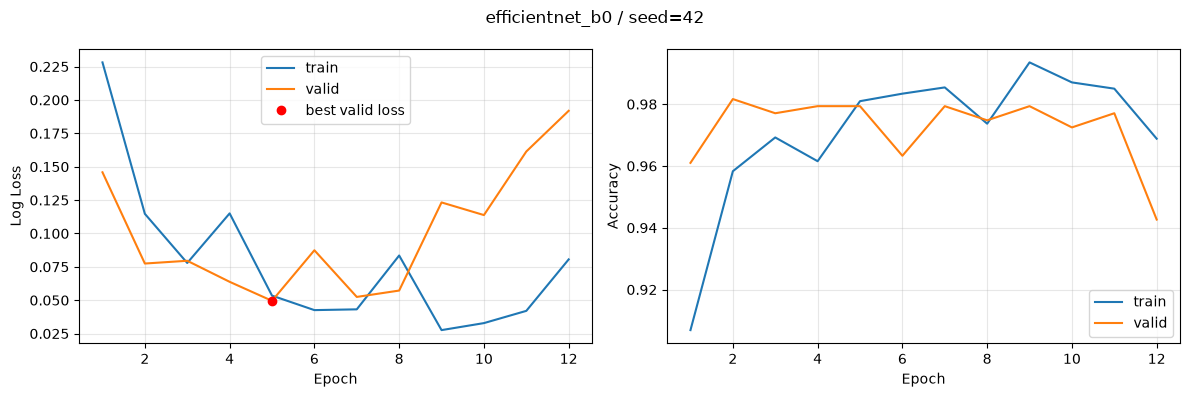


모델: efficientnet_b0 / seed: 43
파라미터 수: 4,008,829

Epoch 1/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.2083 / acc 0.915
valid loss(=log loss) 0.0651 / acc 0.982
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\efficientnet_b0_seed43.pt 저장

Epoch 2/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

... (27 outputs left out)

train loss(=log loss) 0.0638 / acc 0.978
valid loss(=log loss) 0.0661 / acc 0.977

Epoch 12/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.0429 / acc 0.989
valid loss(=log loss) 0.0550 / acc 0.977
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\efficientnet_b0_seed43.pt 저장

학습 완료 (5분 47초)
best: epoch 12, valid log loss 0.0550


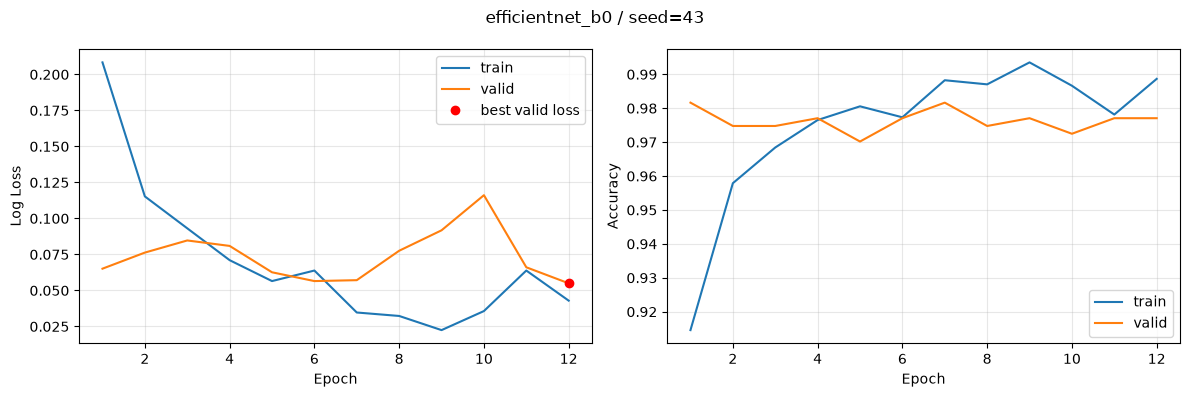


모델: efficientnet_b0 / seed: 44
파라미터 수: 4,008,829

Epoch 1/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.2251 / acc 0.909
valid loss(=log loss) 0.0914 / acc 0.966
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\efficientnet_b0_seed44.pt 저장

Epoch 2/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

... (27 outputs left out)

train loss(=log loss) 0.0488 / acc 0.984
valid loss(=log loss) 0.0679 / acc 0.979

Epoch 12/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.0290 / acc 0.990
valid loss(=log loss) 0.0257 / acc 0.995
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\efficientnet_b0_seed44.pt 저장

학습 완료 (5분 47초)
best: epoch 12, valid log loss 0.0257


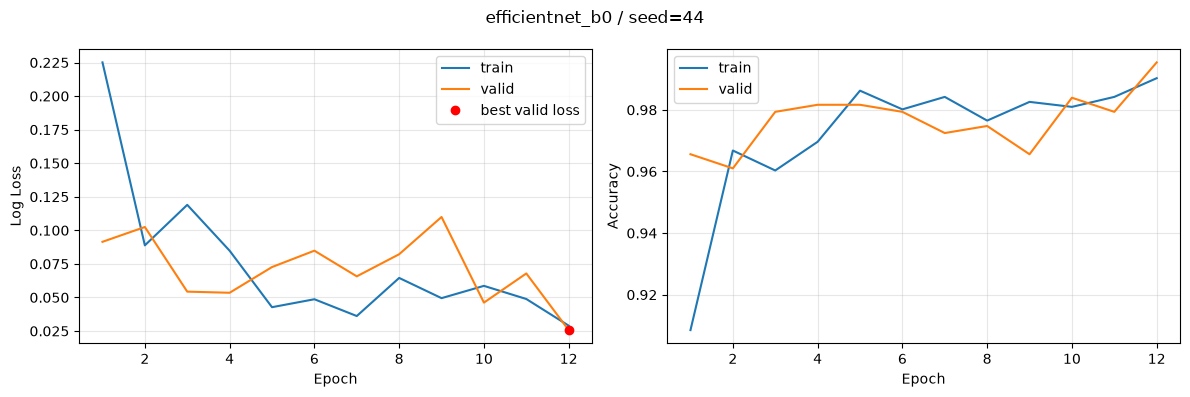


모델: resnet18_places365 / seed: 42
파라미터 수: 11,177,025

Epoch 1/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.3306 / acc 0.861
valid loss(=log loss) 0.4427 / acc 0.764
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\resnet18_places365_seed42.pt 저장

Epoch 2/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

... (27 outputs left out)

train loss(=log loss) 0.0883 / acc 0.972
valid loss(=log loss) 0.1447 / acc 0.947

Epoch 12/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.1173 / acc 0.958
valid loss(=log loss) 0.2666 / acc 0.901

학습 완료 (5분 48초)
best: epoch 8, valid log loss 0.1358


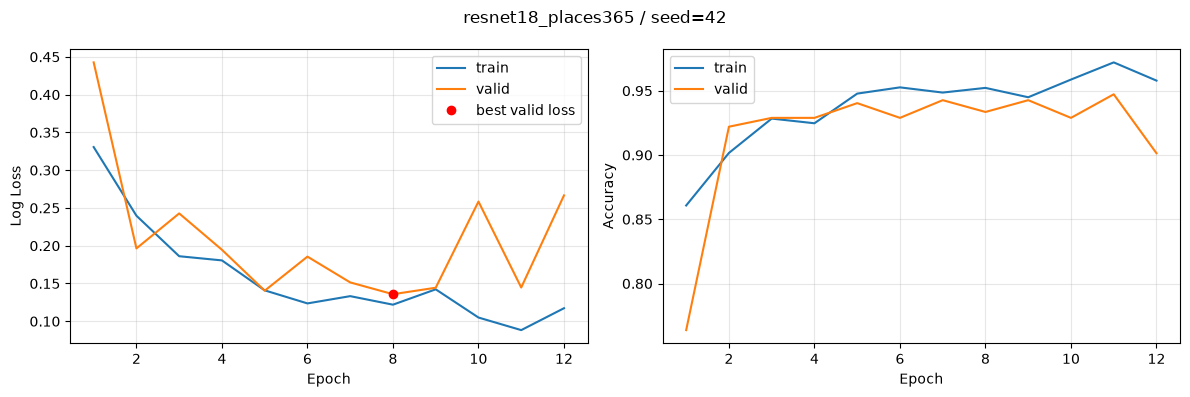


모델: resnet18_places365 / seed: 43
파라미터 수: 11,177,025

Epoch 1/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.3234 / acc 0.861
valid loss(=log loss) 0.3085 / acc 0.860
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\resnet18_places365_seed43.pt 저장

Epoch 2/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

... (27 outputs left out)

train loss(=log loss) 0.1078 / acc 0.962
valid loss(=log loss) 0.1496 / acc 0.940

Epoch 12/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.1277 / acc 0.954
valid loss(=log loss) 0.1018 / acc 0.963
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\resnet18_places365_seed43.pt 저장

학습 완료 (5분 45초)
best: epoch 12, valid log loss 0.1018


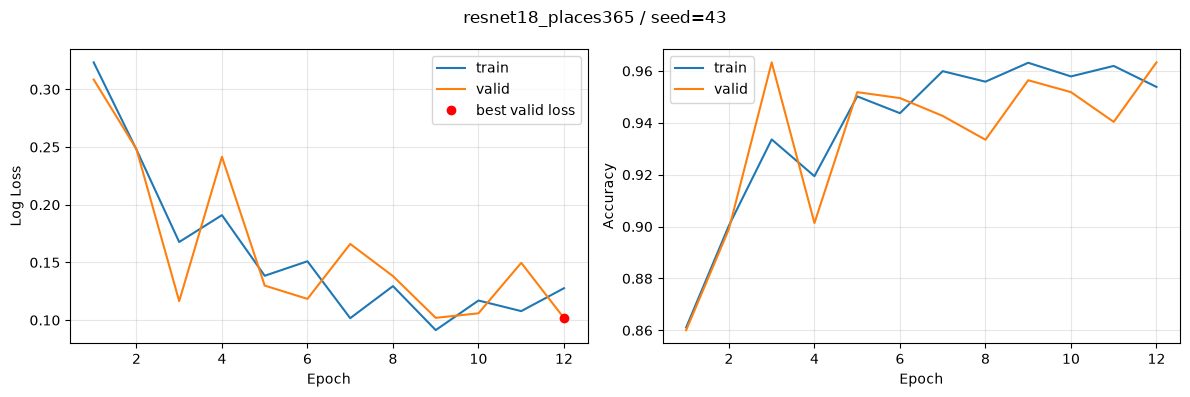


모델: resnet18_places365 / seed: 44
파라미터 수: 11,177,025

Epoch 1/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.3314 / acc 0.862
valid loss(=log loss) 1.4317 / acc 0.665
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\resnet18_places365_seed44.pt 저장

Epoch 2/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

... (27 outputs left out)

train loss(=log loss) 0.1063 / acc 0.959
valid loss(=log loss) 0.1346 / acc 0.956

Epoch 12/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.0994 / acc 0.961
valid loss(=log loss) 0.1991 / acc 0.915

학습 완료 (5분 46초)
best: epoch 5, valid log loss 0.0785


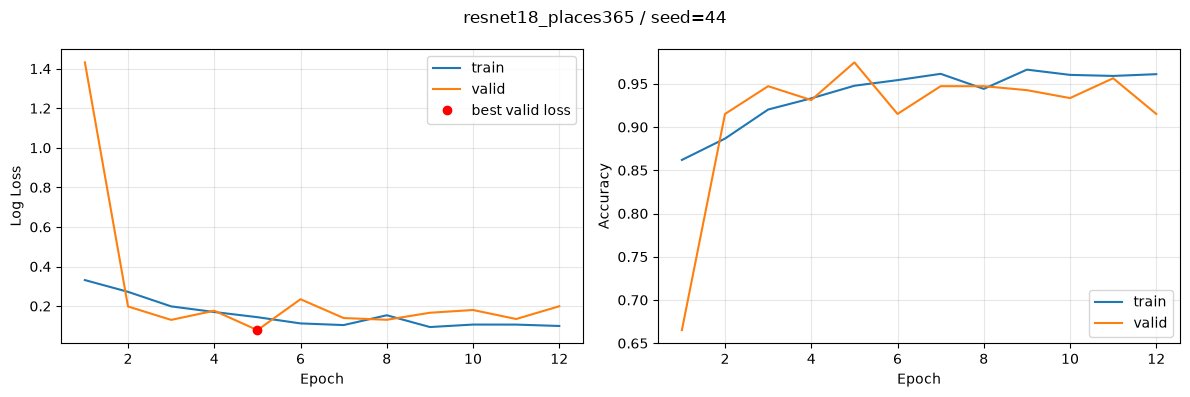


모델: resnet18 / seed: 42
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\행조/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:03<00:00, 11.8MB/s]

파라미터 수: 11,177,025

Epoch 1/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.3828 / acc 0.839
valid loss(=log loss) 0.5993 / acc 0.725
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\resnet18_seed42.pt 저장

Epoch 2/12


... (29 outputs left out)

train loss(=log loss) 0.0691 / acc 0.977
valid loss(=log loss) 0.1454 / acc 0.940

Epoch 12/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.1646 / acc 0.936
valid loss(=log loss) 0.1077 / acc 0.961
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\resnet18_seed42.pt 저장

학습 완료 (5분 52초)
best: epoch 12, valid log loss 0.1077


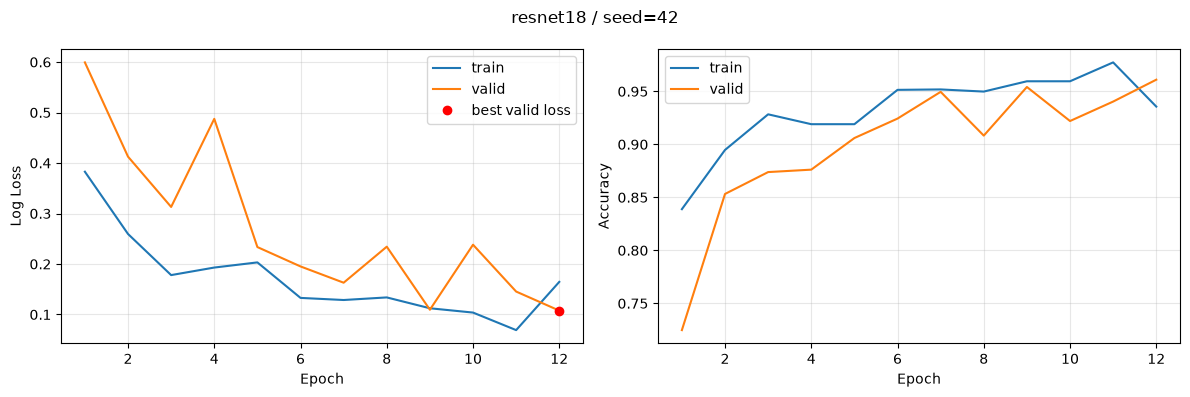


모델: resnet18 / seed: 43
파라미터 수: 11,177,025

Epoch 1/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.3849 / acc 0.834
valid loss(=log loss) 0.2887 / acc 0.874
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\resnet18_seed43.pt 저장

Epoch 2/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

... (27 outputs left out)

train loss(=log loss) 0.1284 / acc 0.950
valid loss(=log loss) 0.1541 / acc 0.952

Epoch 12/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.1318 / acc 0.949
valid loss(=log loss) 0.1745 / acc 0.931

학습 완료 (5분 44초)
best: epoch 6, valid log loss 0.1133


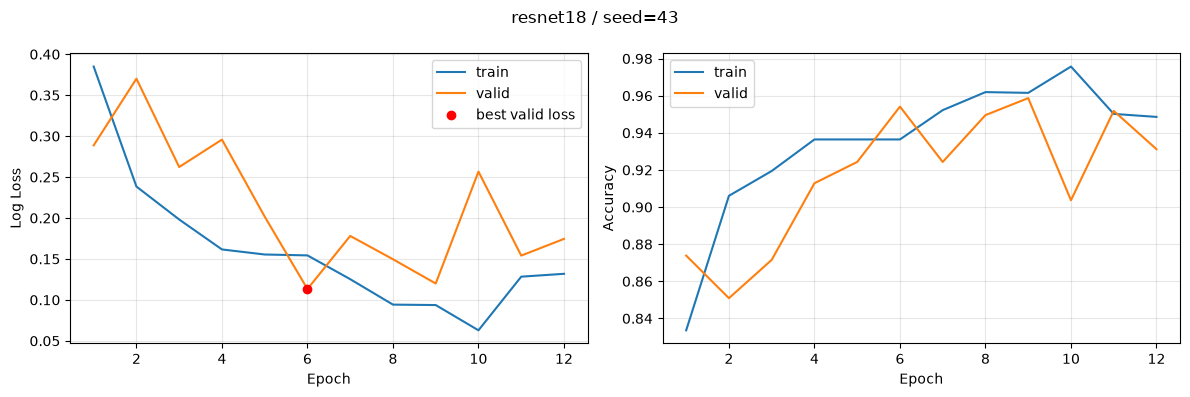


모델: resnet18 / seed: 44
파라미터 수: 11,177,025

Epoch 1/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.4310 / acc 0.828
valid loss(=log loss) 0.5796 / acc 0.833
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\resnet18_seed44.pt 저장

Epoch 2/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

... (27 outputs left out)

train loss(=log loss) 0.1152 / acc 0.958
valid loss(=log loss) 0.1434 / acc 0.945
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\resnet18_seed44.pt 저장

Epoch 12/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.0988 / acc 0.962
valid loss(=log loss) 0.3098 / acc 0.904

학습 완료 (5분 50초)
best: epoch 11, valid log loss 0.1434


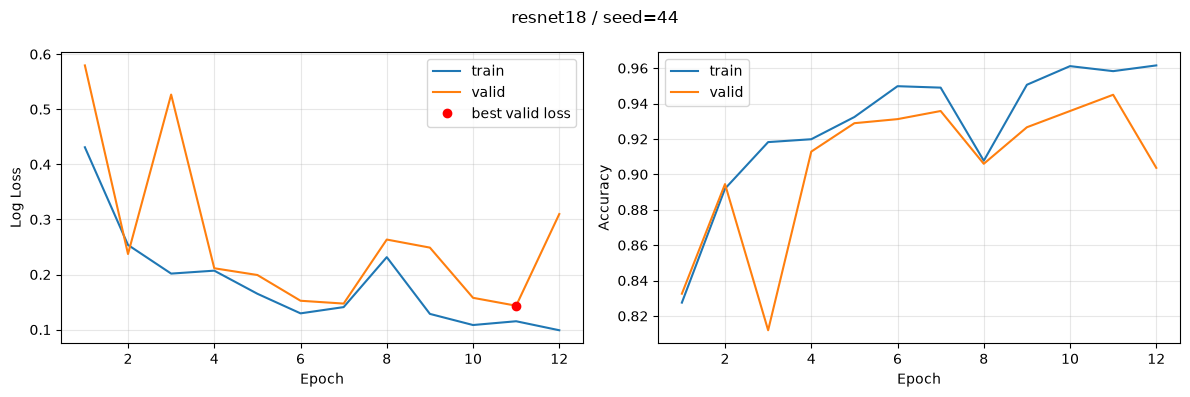


모델: mobilenet_v3_large / seed: 42
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to C:\Users\행조/.cache\torch\hub\checkpoints\mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:01<00:00, 11.8MB/s]

파라미터 수: 4,203,313

Epoch 1/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.2464 / acc 0.892
valid loss(=log loss) 0.7149 / acc 0.821
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\mobilenet_v3_large_seed42.pt 저장

Epoch 2/12


... (29 outputs left out)

train loss(=log loss) 0.0146 / acc 0.994
valid loss(=log loss) 0.0857 / acc 0.972

Epoch 12/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.0728 / acc 0.976
valid loss(=log loss) 0.0644 / acc 0.972
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\mobilenet_v3_large_seed42.pt 저장

학습 완료 (5분 35초)
best: epoch 12, valid log loss 0.0644


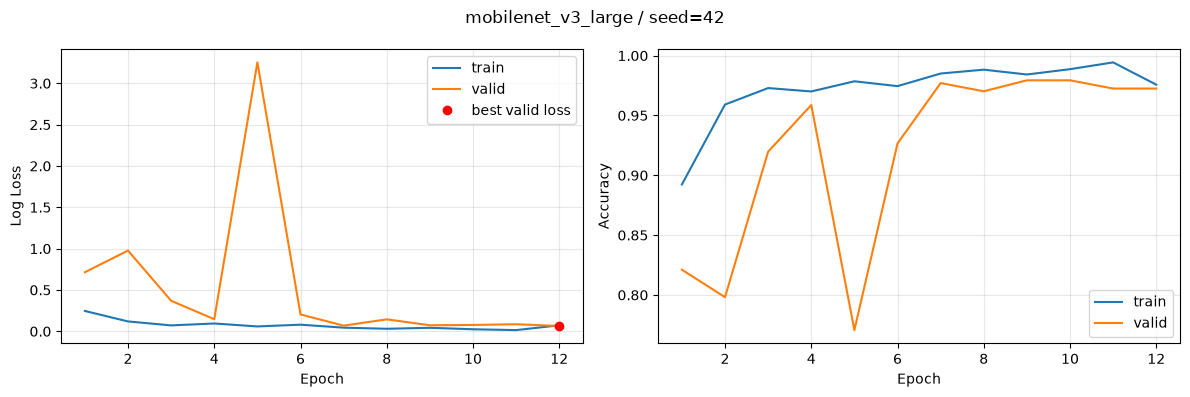


모델: mobilenet_v3_large / seed: 43
파라미터 수: 4,203,313

Epoch 1/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.2098 / acc 0.913
valid loss(=log loss) 0.5887 / acc 0.872
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\mobilenet_v3_large_seed43.pt 저장

Epoch 2/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

... (27 outputs left out)

train loss(=log loss) 0.0436 / acc 0.982
valid loss(=log loss) 0.0956 / acc 0.963

Epoch 12/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.0875 / acc 0.968
valid loss(=log loss) 0.2090 / acc 0.920

학습 완료 (5분 32초)
best: epoch 5, valid log loss 0.0898


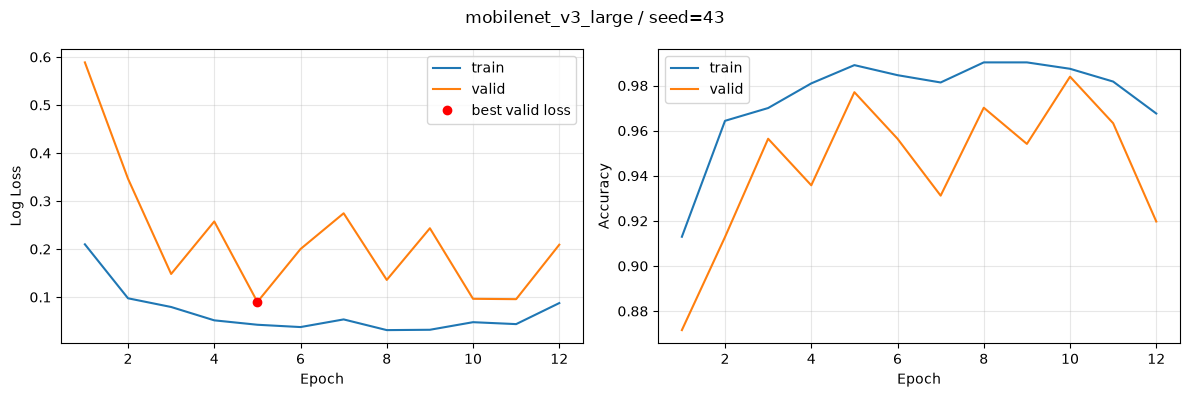


모델: mobilenet_v3_large / seed: 44
파라미터 수: 4,203,313

Epoch 1/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.2378 / acc 0.900
valid loss(=log loss) 1.2081 / acc 0.656
  ↳ best 갱신! \\sshfs.r\luckjo-server@luckjo-server\srv\cloud\Luckjo-Cloud\Workspaces\Codex\AID Study\aid mini challenge\participant_materials\model_comparison\checkpoints\mobilenet_v3_large_seed44.pt 저장

Epoch 2/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

... (27 outputs left out)

train loss(=log loss) 0.0575 / acc 0.980
valid loss(=log loss) 0.2896 / acc 0.931

Epoch 12/12


train:   0%|          | 0/78 [00:00<?, ?it/s]

valid:   0%|          | 0/14 [00:00<?, ?it/s]

train loss(=log loss) 0.0291 / acc 0.989
valid loss(=log loss) 0.2038 / acc 0.952

학습 완료 (5분 39초)
best: epoch 5, valid log loss 0.0649


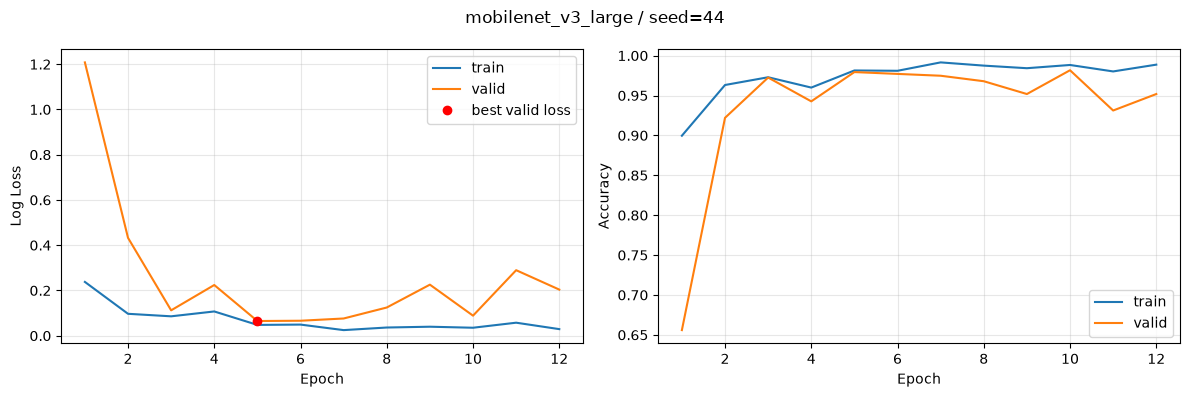

In [17]:
for model_name in MODEL_NAMES:
	for seed in RUN_SEEDS:
		print(f"\n{'=' * 60}")
		print(f"모델: {model_name} / seed: {seed}", flush=True)
		seed_everything(seed)

		model = model_module.build_model(model_name, pretrained=True, places_weight_path=weight_path).to(device)
		n_params = sum(p.numel() for p in model.parameters())
		assert n_params <= PARAM_LIMIT, f"파라미터 제한 초과: {n_params:,}"
		print(f"파라미터 수: {n_params:,}")

		# 모델 생성에서 소비한 난수와 데이터 로딩 난수를 분리합니다.
		seed_everything(seed)
		dataloaders = {
			"train": DataLoader(data_sets["train"], batch_size=params["batch_size"], shuffle=True, num_workers=params["workers"], generator=torch.Generator().manual_seed(seed)),
			"valid": DataLoader(data_sets["valid"], batch_size=params["batch_size"], shuffle=False, num_workers=params["workers"], generator=torch.Generator().manual_seed(seed)),
		}
		criterion = nn.BCEWithLogitsLoss()
		optimizer = torch.optim.Adam(model.parameters(), lr=params["learning_rate"])
		pt_file_name = CHECKPOINT_DIR / f"{model_name}_seed{seed}.pt"

		if device.type == "cuda":
			torch.cuda.synchronize(device)
		started = time.perf_counter()

		with (EPOCH_DIR / f"{model_name}_seed{seed}.csv").open("w", newline="", encoding="utf-8-sig") as epoch_csv:
			history, best_epoch, best_loss = train_model(model, dataloaders, criterion, optimizer, num_epochs=params["epoch"], epoch_csv=epoch_csv)

		if device.type == "cuda":
			torch.cuda.synchronize(device)
		elapsed = time.perf_counter() - started

		results.append({
			"model": model_name,
			"seed": seed,
			"best_epoch": best_epoch,
			"valid_loss": best_loss,
			"valid_acc": history["valid_acc"][best_epoch - 1],
			"seconds": elapsed,
			"n_params": n_params,
			"checkpoint": str(pt_file_name),
		})

		# 실험 도중 중단돼도 완료된 실행의 지표는 CSV에 남깁니다.
		with (RESULT_DIR / "runs.csv").open("w", newline="", encoding="utf-8-sig") as f:
			writer = csv.DictWriter(f, fieldnames=list(results[0]))
			writer.writeheader()
			writer.writerows(results)

		epochs = range(1, len(history["train_loss"]) + 1)
		fig, axes = plt.subplots(1, 2, figsize=(12, 4))
		axes[0].plot(epochs, history["train_loss"], label="train")
		axes[0].plot(epochs, history["valid_loss"], label="valid")
		axes[0].plot(best_epoch, best_loss, "ro", label="best valid loss")
		axes[0].set_ylabel("Log Loss")
		axes[1].plot(epochs, history["train_acc"], label="train")
		axes[1].plot(epochs, history["valid_acc"], label="valid")
		axes[1].set_ylabel("Accuracy")
		for ax in axes:
			ax.set_xlabel("Epoch")
			ax.legend()
			ax.grid(alpha=0.3)
		fig.suptitle(f"{model_name} / seed={seed}")
		fig.tight_layout()
		fig.savefig(GRAPH_DIR / f"{model_name}_seed{seed}.png", dpi=160, bbox_inches="tight")
		plt.show()
		plt.close(fig)
		del optimizer, model, dataloaders


### 전체 통계와 비교 그래프

각 실행의 최저 검증 Log Loss와 해당 epoch의 정확도를 집계합니다.
모델별 평균과 표본 표준편차를 `summary.csv`에 저장하고, 평균 검증 Log Loss가 낮은 순서로 표시합니다.
오차 막대는 시드 3개 사이의 표준편차이며 신뢰구간이 아닙니다.


In [ ]:
assert len(results) == len(MODEL_NAMES) * len(RUN_SEEDS), "모든 비교 실험을 완료해야 합니다."

summary = []
for model_name in MODEL_NAMES:
	runs = [row for row in results if row["model"] == model_name]
	losses = np.array([row["valid_loss"] for row in runs])
	accuracies = np.array([row["valid_acc"] for row in runs])
	seconds = np.array([row["seconds"] for row in runs])
	summary.append({
		"model": model_name,
		"runs": len(runs),
		"loss_mean": float(losses.mean()),
		"loss_std": float(losses.std(ddof=1)),
		"accuracy_mean": float(accuracies.mean()),
		"accuracy_std": float(accuracies.std(ddof=1)),
		"seconds_mean": float(seconds.mean()),
		"seconds_std": float(seconds.std(ddof=1)),
		"n_params": runs[0]["n_params"],
	})

summary.sort(key=lambda row: row["loss_mean"])
with (RESULT_DIR / "summary.csv").open("w", newline="", encoding="utf-8-sig") as f:
	writer = csv.DictWriter(f, fieldnames=list(summary[0]))
	writer.writeheader()
	writer.writerows(summary)

print("평균 검증 Log Loss 오름차순")
print(f"{'Model':<24} {'Log Loss: mean ± SD':<24} {'Accuracy: mean ± SD':<24} {'Time: mean ± SD'}")
for row in summary:
	loss_text = f"{row['loss_mean']:.4f} ± {row['loss_std']:.4f}"
	acc_text = f"{row['accuracy_mean']:.2%} ± {row['accuracy_std']:.2%}"
	time_text = f"{row['seconds_mean'] / 60:.1f} ± {row['seconds_std'] / 60:.1f} min"
	print(f"{row['model']:<24} {loss_text:<24} {acc_text:<24} {time_text}")

x = np.arange(len(summary))
names = [row["model"] for row in summary]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(x, [row["loss_mean"] for row in summary], yerr=[row["loss_std"] for row in summary], capsize=5)
axes[0].set_title("Best validation Log Loss: mean ± SD")
axes[0].set_ylabel("Log Loss (lower is better)")
axes[1].bar(x, [row["accuracy_mean"] for row in summary], yerr=[row["accuracy_std"] for row in summary], capsize=5)
axes[1].set_title("Accuracy at best loss: mean ± SD")
axes[1].set_ylabel("Accuracy")
for ax in axes:
	ax.set_xticks(x, names, rotation=20, ha="right")
	ax.grid(axis="y", alpha=0.3)
	ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(GRAPH_DIR / "comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"\n전체 학습 시간: {sum(row['seconds'] for row in results) / 60:.1f}분")
print("전체 결과:", RESULT_DIR / "runs.csv")
print("모델별 통계:", RESULT_DIR / "summary.csv")
print("그래프 폴더:", GRAPH_DIR)


### 추론·제출에 사용할 모델 선택

기본값은 평균 검증 Log Loss가 가장 낮은 모델입니다. 다른 모델을 사용하려면 아래 `selected_model_name`에 모델명을 직접 지정하세요.
선택한 모델의 3회 실행 중 검증 Log Loss가 가장 낮은 가중치를 사용합니다. 앙상블하지 않습니다.


In [ ]:
selected_model_name = summary[0]["model"]

selected_run = min((row for row in results if row["model"] == selected_model_name), key=lambda row: row["valid_loss"])
pt_file_name = Path(selected_run["checkpoint"])
assert pt_file_name.is_file(), f"선택한 가중치 파일이 없습니다: {pt_file_name}"

print("선택 모델:", selected_model_name)
print("선택 시드:", selected_run["seed"])
print("검증 Log Loss:", selected_run["valid_loss"])
print("가중치:", pt_file_name)


## 테스트 추론 → `submission.csv` 생성

리더보드 제출 형식은 `id,prob` 입니다. `prob`은 **IT관(=1)일 확률**입니다. 제출은 **10분에 1회, 하루 최대 50회**입니다.

```
id,prob
f81d4fae-7dec-41d0-a765-00a0c91e6bf6,0.831250
c9b1f2e8-3a45-4d67-b012-5e6f7a8b9c0d,0.024113
```

> 채점 시 확률은 [1e-6, 1-1e-6]로 클리핑되지만, 0이나 1에 극단적으로 붙은 확신은 한 장만 틀려도 log loss를 크게 망가뜨립니다. 모델이 과확신하지 않는지 확인해 보세요.

In [ ]:
class TestImageDataset(Dataset):
    def __init__(self, files, transform):
        self.files = files
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        file = self.files[index]
        img = Image.open(file).convert('RGB')
        return self.transform(img), os.path.basename(file)


import glob
test_files = sorted(glob.glob('./test/*'))
print('테스트 이미지 수:', len(test_files))

test_loader = DataLoader(
    TestImageDataset(test_files, valid_transform),
    batch_size=params['batch_size'], shuffle=False)

In [ ]:
# 검증 성적이 가장 좋았던 시점의 가중치를 불러와 추론합니다
best_model = model_module.build_model(selected_model_name, pretrained=False)
best_model.load_state_dict(torch.load(pt_file_name, map_location=device, weights_only=True))
best_model = best_model.to(device)
best_model.eval()

rows = ['id,prob']
with torch.no_grad():
    for inputs, filenames in test_loader:
        probs = torch.sigmoid(best_model(inputs.to(device))).squeeze(1)
        for name, p in zip(filenames, probs):
            rows.append(f'{os.path.splitext(name)[0]},{p.item():.6f}')

with open('submission.csv', 'w') as f:
    f.write('\n'.join(rows) + '\n')

print('submission.csv 생성 완료 — 리더보드에 이 파일을 제출하세요.')
print('\n'.join(rows[:6]))

## 최종 파일 생성 (예시: `predict.py` 패키지)

마감 후 운영진이 **모든 참가자의 최종 파일**을 받아 **Colab CPU** 환경에서 직접 실행합니다.

1. 공개 리더보드(Public) 점수가 재현되는지 확인
2. 런타임(테스트 500장 10분 이내)과 파라미터 수(20M 이하) 확인
3. 통과한 참가자만 Private 250장 점수로 최종 순위 산정

**제출 형식은 자유**입니다. 운영진이 실행할 수 있고 가중치가 포함되어 있으면 됩니다. 아래는 이 노트북이 만드는 예시 형식이며, 이렇게 내면 다음 명령 한 줄로 검증됩니다.

```shell
python predict.py --input <이미지 폴더> --output pred.csv
```

패키지 구성:
```
📦submission_package.zip
 ├─📜model.py     # 모델 구조 정의 (build_model 함수 필수)
 ├─📜predict.py   # 추론 진입점 (--input/--output 인터페이스 유지)
 └─📜model.pt     # 학습된 가중치 (사전학습 가중치 사용 시에도 여기에 포함)
```

In [ ]:
%%writefile predict.py
# 이 셀은 predict.py 파일을 생성합니다 (모델 패키지에 포함되는 파일).
# 운영진은 Colab CPU 에서 이 파일을 실행해 공개 점수 재현·런타임·파라미터 수를 확인합니다:
#   python predict.py --input <이미지 폴더> --output pred.csv
#
# 전처리·TTA 등 추론 로직을 바꾸고 싶다면 이 파일을 수정하면 됩니다.
# 제출 형식은 자유지만, 출력 CSV 는 id,prob 형식이어야 채점할 수 있습니다.
import argparse
import glob
import os

import torch
from PIL import Image
from torchvision import transforms

from model import IMG_SIZE, NORM_MEAN, NORM_STD, build_model

PARAM_LIMIT = 20_000_000


def load_images(input_dir):
    # 확장자를 소문자로 비교 -> OS 에 상관없이 한 파일은 한 번만 잡힌다
    exts = (".jpg", ".jpeg", ".png")
    return sorted(f for f in glob.glob(os.path.join(input_dir, "*"))
                  if f.lower().endswith(exts))


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--input", required=True, help="테스트 이미지 폴더")
    parser.add_argument("--output", required=True, help="출력 CSV 경로")
    parser.add_argument("--weights", default="model.pt", help="모델 가중치 파일")
    args = parser.parse_args()

    device = torch.device("cpu")  # 검증은 Colab CPU 기준입니다

    weights_path = os.path.join(os.path.dirname(os.path.abspath(__file__)), args.weights)
    model = build_model()
    model.load_state_dict(torch.load(weights_path, map_location=device))
    model.to(device)
    model.eval()

    n_params = sum(p.numel() for p in model.parameters())
    print(f"파라미터 수: {n_params:,} (제한 {PARAM_LIMIT:,})")
    assert n_params <= PARAM_LIMIT, "파라미터 20M 초과! 실격 대상입니다."

    # 학습 때의 valid_transform과 동일한 전처리 (다르면 채점 때 점수가 무너집니다)
    transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(NORM_MEAN, NORM_STD),
    ])

    files = load_images(args.input)
    assert len(files) > 0, f"{args.input} 에서 이미지를 찾지 못했습니다."

    rows = ["id,prob"]
    with torch.no_grad():
        for i in range(0, len(files), 32):
            batch_files = files[i:i + 32]
            batch = torch.stack([
                transform(Image.open(f).convert("RGB")) for f in batch_files
            ]).to(device)
            probs = torch.sigmoid(model(batch)).squeeze(1)
            for f, p in zip(batch_files, probs):
                rows.append(f"{os.path.splitext(os.path.basename(f))[0]},{p.item():.6f}")

    with open(args.output, "w") as fp:
        fp.write("\n".join(rows) + "\n")
    print(f"{args.output} 저장 완료 ({len(files)}장)")


if __name__ == "__main__":
    main()


In [ ]:
# 패키지 폴더 구성 및 압축
if os.path.exists('package'):
    shutil.rmtree('package')
os.makedirs('package')
for f in ['model.py', 'predict.py']:
	shutil.copy(f, 'package/')
shutil.copyfile(pt_file_name, 'package/model.pt')

# 패키지의 기본 모델을 선택한 구조에 맞춥니다.
package_model_path = Path('package/model.py')
package_model_source = package_model_path.read_text(encoding='utf-8')
default_model_line = 'MODEL_NAME = "efficientnet_b0"'
assert package_model_source.count(default_model_line) == 1, 'model.py의 MODEL_NAME 정의를 확인하세요.'
package_model_source = package_model_source.replace(default_model_line, f'MODEL_NAME = {selected_model_name!r}', 1)
package_model_path.write_text(package_model_source, encoding='utf-8')

zip_path = shutil.make_archive('submission_package', 'zip', 'package')
print('패키지 생성 완료:', zip_path)
print('내용물:', sorted(os.listdir('package')))

### 패키지 자가 검증 (제출 전 필수!)

운영진 검증과 같은 방식으로, 패키지 폴더 안에서 `predict.py`를 CPU로 실행해 봅니다. 여기서 에러가 나면 검증도 실패합니다. Colab 런타임을 CPU로 두고 실행하면 10분 기준도 함께 확인할 수 있습니다.

In [ ]:
import sys
result = subprocess.run(
    [sys.executable, 'predict.py', '--input', '../test', '--output', '../package_check.csv'],
    cwd='package', capture_output=True, text=True)
print(result.stdout)
print(result.stderr)
assert result.returncode == 0, 'predict.py 실행 실패! 패키지를 점검하세요.'

# 노트북 추론 결과와 패키지 추론 결과가 (허용 오차 내에서) 일치하는지 확인
# GPU로 학습·추론한 경우 CPU 추론과 부동소수점 미세 차이가 나는 것은 정상입니다
def read_probs(path):
    with open(path) as f:
        next(f)  # header
        return {line.split(',')[0]: float(line.split(',')[1]) for line in f if line.strip()}

nb_probs = read_probs('submission.csv')
pkg_probs = read_probs('package_check.csv')
assert nb_probs.keys() == pkg_probs.keys(), '파일 목록이 다릅니다!'
max_diff = max(abs(nb_probs[k] - pkg_probs[k]) for k in nb_probs)
print(f'노트북 vs 패키지 확률 최대 차이: {max_diff:.2e}')
assert max_diff < 1e-3, '차이가 너무 큽니다 — 전처리나 가중치가 어긋났는지 확인하세요.'
print('패키지 자가 검증 통과 ✓')

## 제출 전 체크리스트

- [ ] `submission.csv`가 `id,prob` 형식이고 테스트 500장 전부를 포함하는가?
- [ ] 파라미터 카운터 셀에서 **20M 이하**를 확인했는가? (앙상블·사전학습 백본 합산)
- [ ] 패키지 자가 검증 셀이 에러 없이 통과했는가? (Colab CPU 에서 500장 10분 이내)
- [ ] `predict.py`가 네트워크 없이 동작하는가? (다운로드 코드 금지, 가중치는 패키지에 동봉)
- [ ] 테스트 이미지를 학습에 사용하지 않았는가? (pseudo-labeling 포함 금지)
- [ ] 외부 이미지를 학습에 사용하지 않았는가?

## 개선 아이디어

- 채널 수·블록 수 조정, 학습률 스케줄러(CosineAnnealing 등) 추가
- 20M 이내의 사전학습 백본(MobileNetV3, EfficientNet-B0 등) fine-tuning — 가중치를 패키지에 포함할 것
- 증강 다양화: 밝기·색감·회전·노이즈 — 처음 보는 촬영 조건에 대한 일반화
- 검증 전략 개선: k-fold 교차검증으로 점수 추정의 신뢰도 높이기
- 과확신 완화: label smoothing, 확률 클리핑, 온도 조절(temperature scaling)
